# EDA: what can the dealer say about these cars?

The dealer uses this data to find the positive traits of a car when talking to a customer.
This notebook asks which selling points exist in the stock, which cars have them, and which trade-offs limit them.
The answers point to the tools in `server.py` that bring each selling point up.

Units: `mpg` is miles per gallon (higher uses less fuel), `liters_per_100km` is litres per 100 km (lower uses less fuel), `weight` is pounds, `displacement` is cubic inches, `acceleration` is seconds from 0 to 60 mph (lower is faster).

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

cars = pd.read_csv(Path("../data/Automobile.csv"))
# Same conversion as server.py: Norwegian customers think in litres per 100 km
cars["liters_per_100km"] = (235.215 / cars["mpg"]).round(1)

ORIGINS = ["usa", "japan", "europe"]
ORIGIN_COLORS = {"usa": "#257de0", "japan": "#f47230", "europe": "#00b894"}
SINGLE_COLOR = "#257de0"
INK = "#191919"
MUTED = "#666666"

plt.rcParams.update(
    {
        "figure.figsize": (7, 4),
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c2c2c2",
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e7e7e7",
        "grid.linewidth": 0.8,
        "text.color": INK,
        "axes.titlecolor": INK,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
        "lines.linewidth": 2,
    }
)

## Overview

How big is the dataset and what do the values look like?

In [2]:
cars.shape

(398, 10)

In [3]:
cars.head()

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,liters_per_100km
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,70,usa,13.1
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,70,usa,15.7
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,70,usa,13.1
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,70,usa,14.7
4,ford torino,17.0,8,302.0,140.0,3449,10.5,70,usa,13.8


In [4]:
cars.describe().round(1)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,liters_per_100km
count,398.0,398.0,398.0,392.0,398.0,398.0,398.0,398.0
mean,23.5,5.5,193.4,104.5,2970.4,15.6,76.0,11.2
std,7.8,1.7,104.3,38.5,846.8,2.8,3.7,3.9
min,9.0,3.0,68.0,46.0,1613.0,8.0,70.0,5.0
25%,17.5,4.0,104.2,75.0,2223.8,13.8,73.0,8.1
50%,23.0,4.0,148.5,93.5,2803.5,15.5,76.0,10.2
75%,29.0,8.0,262.0,126.0,3608.0,17.2,79.0,13.4
max,46.6,8.0,455.0,230.0,5140.0,24.8,82.0,26.1


**Finding:** 398 cars and 10 columns (the 9 in the file plus `liters_per_100km`). Fuel use runs from 5.0 to 26.1 litres per 100 km and horsepower from 46 to 230, so the stock spans small economy cars to big eight-cylinder cars.

## Data quality

Missing values, and whether a car name points to one row or several.

In [5]:
cars.isna().sum()

name                0
mpg                 0
cylinders           0
displacement        0
horsepower          6
weight              0
acceleration        0
model_year          0
origin              0
liters_per_100km    0
dtype: int64

In [6]:
cars[cars["horsepower"].isna()]

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,liters_per_100km
32,ford pinto,25.0,4,98.0,NaN,2046,19.0,71,usa,9.4
126,ford maverick,21.0,6,200.0,NaN,2875,17.0,74,usa,11.2
330,renault lecar deluxe,40.9,4,85.0,NaN,1835,17.3,80,europe,5.8
336,ford mustang cobra,23.6,4,140.0,NaN,2905,14.3,80,usa,10.0
354,renault 18i,34.5,4,100.0,NaN,2320,15.8,81,europe,6.8
374,amc concord dl,23.0,4,151.0,NaN,3035,20.5,82,usa,10.2


In [7]:
print("Rows:", len(cars))
print("Unique names:", cars["name"].nunique())

Rows: 398
Unique names: 305


**Finding:** 
- Only `horsepower` has gaps, in 6 cars. `most_horsepower` drops those rows, and the other tools return their horsepower as null.
- 305 unique names for 398 rows, so some names appear in several model years. A name lookup (`car_highlights`, `compare_cars`) picks the newest model year.

## Where the cars come from

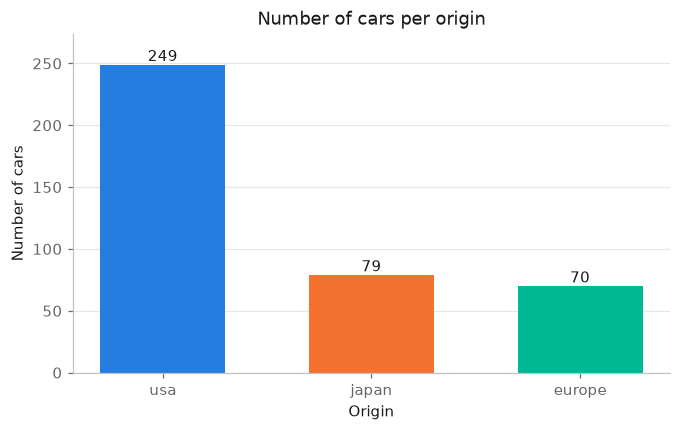

In [8]:
counts = cars["origin"].value_counts().reindex(ORIGINS)

fig, ax = plt.subplots()
bars = ax.bar(
    counts.index, counts.values, width=0.6, color=[ORIGIN_COLORS[o] for o in ORIGINS]
)
ax.bar_label(bars, color=INK)
ax.margins(y=0.1)
ax.set_title("Number of cars per origin")
ax.set_xlabel("Origin")
ax.set_ylabel("Number of cars")
plt.show()

**Finding:** usa has 249 of the 398 cars, more than japan (79) and europe (70) combined. Most customers will be looking at an American car.

## Origin profile

What a typical car from each origin looks like on the selling-point measures.

In [9]:
profile = (
    cars.groupby("origin")[["liters_per_100km", "horsepower", "weight", "acceleration"]]
    .mean()
    .reindex(ORIGINS)
    .round(1)
)
profile

,liters_per_100km,horsepower,weight,acceleration
origin,,,,
usa,12.9,119.0,3361.9,15.0
japan,8.1,79.8,2221.2,16.2
europe,8.9,80.6,2423.3,16.8


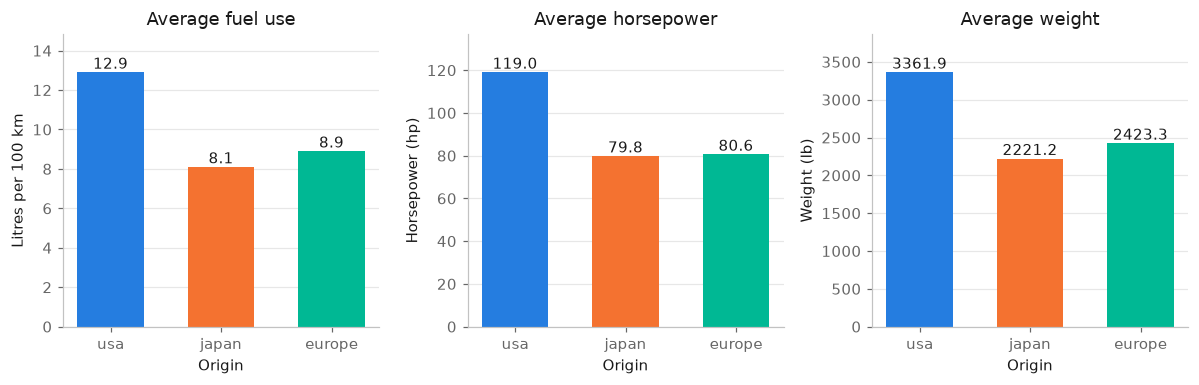

In [10]:
panels = [
    ("liters_per_100km", "Average fuel use", "Litres per 100 km"),
    ("horsepower", "Average horsepower", "Horsepower (hp)"),
    ("weight", "Average weight", "Weight (lb)"),
]
colors = [ORIGIN_COLORS[o] for o in ORIGINS]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (column, title, unit) in zip(axes, panels):
    bars = ax.bar(profile.index, profile[column], width=0.6, color=colors)
    ax.bar_label(bars, fmt="%.1f", color=INK)
    ax.set_title(title)
    ax.set_xlabel("Origin")
    ax.set_ylabel(unit)
    ax.margins(y=0.15)
fig.tight_layout()
plt.show()

**Finding:** 
- Japanese cars use the least fuel (8.1 litres per 100 km) and are the lightest (2221.2 lb). European cars are close behind (8.9 and 2423.3).
- American cars have the most horsepower (119.0) and the quickest 0-60 mph (15.0 s), but also use the most fuel (12.9) and weigh the most (3361.9 lb).
- So "economical" and "light" are mostly Japanese and European selling points, "powerful" and "quick" mostly American ones.

## Fuel use by origin

The averages hide the spread, so look at the full range of mpg per origin.

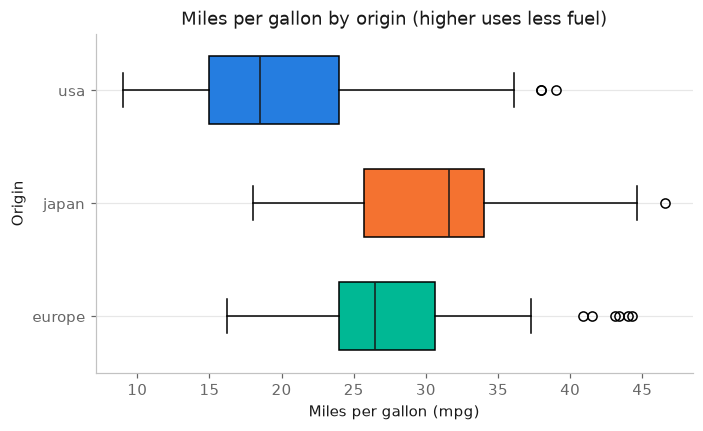

In [11]:
fig, ax = plt.subplots()
boxes = ax.boxplot(
    [cars.loc[cars["origin"] == o, "mpg"] for o in ORIGINS],
    tick_labels=ORIGINS,
    orientation="horizontal",
    patch_artist=True,
    widths=0.6,
    medianprops={"color": INK},
)
for box, origin in zip(boxes["boxes"], ORIGINS):
    box.set_facecolor(ORIGIN_COLORS[origin])
ax.invert_yaxis()  # usa on top, same order as the other charts
ax.set_title("Miles per gallon by origin (higher uses less fuel)")
ax.set_xlabel("Miles per gallon (mpg)")
ax.set_ylabel("Origin")
plt.show()

**Finding:** The American box sits clearly to the left: a typical American car uses more fuel than most Japanese and European cars. Japan has the highest median and holds the most economical car in the stock (46.6 mpg, the maximum in `describe()`).

## Change over model years

Did the cars get more economical or more powerful over time?

In [12]:
by_year = cars.groupby("model_year")[["mpg", "horsepower"]].mean().round(1)
by_year

,mpg,horsepower
model_year,,
70,17.7,147.8
71,21.2,107.0
72,18.7,120.2
73,17.1,130.5
74,22.7,94.2
75,20.3,101.1
76,21.6,101.1
77,23.4,105.1
78,24.1,99.7


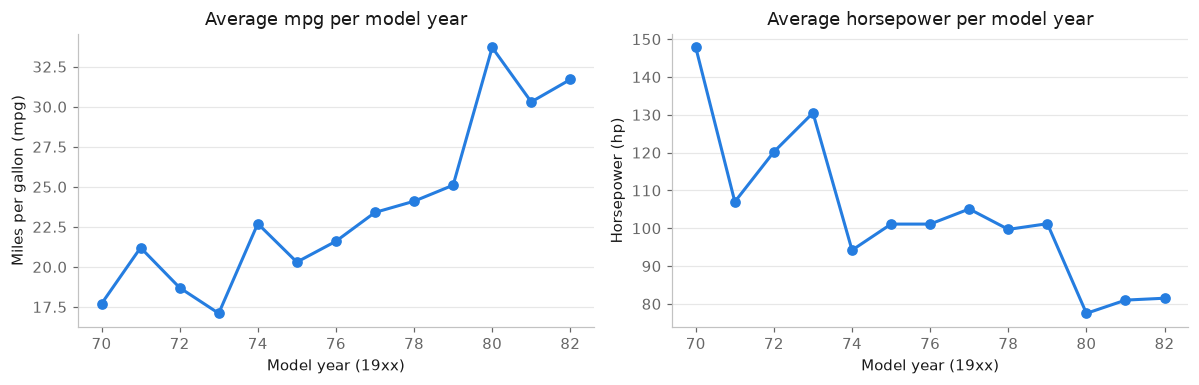

In [13]:
fig, (ax_mpg, ax_hp) = plt.subplots(1, 2, figsize=(11, 3.6))

ax_mpg.plot(by_year.index, by_year["mpg"], marker="o", color=SINGLE_COLOR)
ax_mpg.set_title("Average mpg per model year")
ax_mpg.set_xlabel("Model year (19xx)")
ax_mpg.set_ylabel("Miles per gallon (mpg)")

ax_hp.plot(by_year.index, by_year["horsepower"], marker="o", color=SINGLE_COLOR)
ax_hp.set_title("Average horsepower per model year")
ax_hp.set_xlabel("Model year (19xx)")
ax_hp.set_ylabel("Horsepower (hp)")

fig.tight_layout()
plt.show()

**Finding:** Average mpg rose from 17.7 in 1970 to 31.7 in 1982, while average horsepower fell from 147.8 to 81.5. The biggest jump is from 1979 (25.1 mpg) to 1980 (33.7 mpg), so the newest cars are the economical ones.

## The trade-off

Can a car be both economical and powerful?

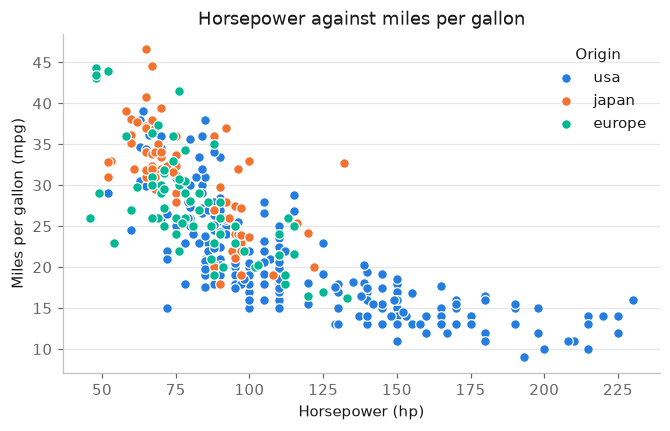

In [14]:
fig, ax = plt.subplots()
for origin in ORIGINS:
    subset = cars[cars["origin"] == origin]
    ax.scatter(
        subset["horsepower"],
        subset["mpg"],
        s=40,
        color=ORIGIN_COLORS[origin],
        edgecolor="white",
        linewidth=0.8,
        label=origin,
    )
ax.set_title("Horsepower against miles per gallon")
ax.set_xlabel("Horsepower (hp)")
ax.set_ylabel("Miles per gallon (mpg)")
ax.legend(title="Origin")
plt.show()

In [15]:
# Correlation with mpg; liters_per_100km is left out because it is computed from mpg
cars.corr(numeric_only=True)["mpg"].drop(["mpg", "liters_per_100km"]).sort_values()

weight         -0.831741
displacement   -0.804203
horsepower     -0.778427
cylinders      -0.775396
acceleration    0.420289
model_year      0.579267
Name: mpg, dtype: float64

**Finding:** mpg falls as horsepower rises: the correlation is -0.78 with horsepower and -0.83 with weight. The top right of the scatter plot is almost empty, so a car that is both economical and powerful is rare and worth pointing out.

## All-rounders

Cars above the median on both mpg and horsepower: economical and still strong.

In [16]:
mpg_median = cars["mpg"].median()
hp_median = cars["horsepower"].median()
print("Median mpg:", mpg_median, "| median horsepower:", hp_median)

all_rounders = cars[(cars["mpg"] > mpg_median) & (cars["horsepower"] > hp_median)]
print("All-rounders:", len(all_rounders))
print(all_rounders["origin"].value_counts().reindex(ORIGINS).to_dict())
all_rounders[["name", "mpg", "horsepower", "model_year", "origin"]].sort_values(
    "mpg", ascending=False
)

Median mpg: 23.0 | median horsepower: 93.5
All-rounders: 27
{'usa': 8, 'japan': 15, 'europe': 4}


,name,mpg,horsepower,model_year,origin
357,datsun 200sx,32.9,100.0,81,japan
333,datsun 280-zx,32.7,132.0,80,japan
390,toyota celica gt,32.0,96.0,82,japan
306,chevrolet citation,28.8,115.0,79,usa
323,dodge colt,27.9,105.0,80,usa
267,toyota corona,27.5,95.0,78,japan
268,datsun 510,27.2,97.0,78,japan
307,oldsmobile omega brougham,26.8,115.0,79,usa
364,oldsmobile cutlass ls,26.6,105.0,81,usa
23,bmw 2002,26.0,113.0,70,europe


**Finding:** 27 cars beat the median on both mpg (23.0) and horsepower (93.5); 15 of them are Japanese, and the top three are all Japanese, led by the datsun 200sx (32.9 mpg, 100 hp). The dealer can list them with `search_cars(min_mpg=23.1, min_horsepower=94, limit=50)`.

## Does every car have a selling point?

`car_highlights` calls a metric a selling point when the car beats at least 75 % of the cars in stock on it.
The same rule in a few lines: for mpg and horsepower higher is better, for acceleration and weight lower is better.

In [17]:
# column -> higher_is_better, same as HIGHLIGHT_METRICS in server.py
METRICS = {"mpg": True, "horsepower": True, "acceleration": False, "weight": False}

beats = pd.DataFrame(index=cars.index)
for column, higher_is_better in METRICS.items():
    values = cars[column].dropna()
    percents = []
    for value in cars[column]:
        if higher_is_better:
            beaten = values < value
        else:
            beaten = values > value
        percents.append(round(beaten.mean() * 100))
    beats[column] = percents

# A missing value beats nobody, so it never counts as strong (the server skips it)
cars["strong_metrics"] = (beats >= 75).sum(axis=1)
strong_counts = cars["strong_metrics"].value_counts().reindex(range(5), fill_value=0)
strong_counts

strong_metrics
0    155
1     94
2    145
3      4
4      0
Name: count, dtype: int64

Cars with at least one selling point: 61.1 %


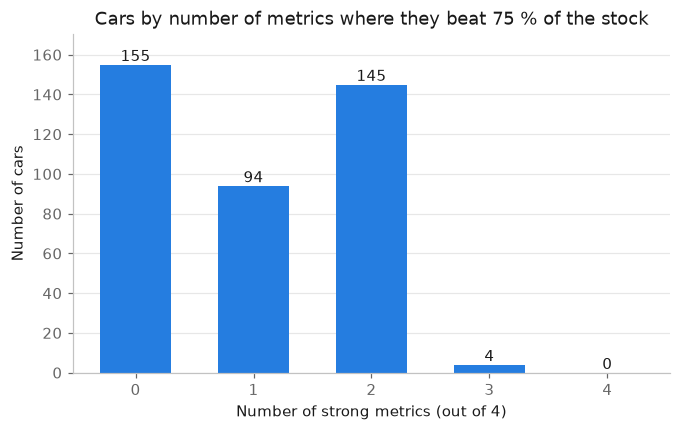

In [18]:
share = (cars["strong_metrics"] >= 1).mean() * 100
print(f"Cars with at least one selling point: {share:.1f} %")

fig, ax = plt.subplots()
bars = ax.bar(strong_counts.index, strong_counts.values, width=0.6, color=SINGLE_COLOR)
ax.bar_label(bars, color=INK)
ax.margins(y=0.1)
ax.set_title("Cars by number of metrics where they beat 75 % of the stock")
ax.set_xlabel("Number of strong metrics (out of 4)")
ax.set_ylabel("Number of cars")
plt.show()

**Finding:** 
- 61.1 % of the cars beat at least 75 % of the stock on at least one metric, so `car_highlights` has a real selling point for them.
- The other 155 cars have no strong metric. For them `car_highlights` falls back to the car's single best metric, so the assistant still has something positive to say.
- No car is strong on all four metrics, and only 4 are strong on three.

## Summary

| Finding | What the dealer can say | Tool that surfaces it |
|---|---|---|
| Japanese and European cars use less fuel and weigh less (8.1 and 8.9 vs 12.9 litres per 100 km) | "This car uses less fuel than most cars we have" | `origin_statistics`, `car_highlights` |
| American cars have the most horsepower (119.0 on average) and the quickest 0-60 mph | "One of the strongest and quickest cars in stock" | `most_horsepower`, `fastest_acceleration` |
| Power and fuel economy pull in opposite directions (correlation -0.78) | "Economical and still strong, which is rare" | `search_cars` with `min_mpg` and `min_horsepower` |
| 27 all-rounders beat the median on both mpg and horsepower | "Above average on both fuel use and power" | `search_cars(min_mpg=23.1, min_horsepower=94)` |
| 61.1 % of the cars beat 75 % of the stock on at least one metric | "Lighter than most of the cars in stock" | `car_highlights` |
| 155 cars have no metric at 75 % | Lead with the car's best metric, or compare it with a specific rival | `car_highlights` (fallback), `compare_cars` |

### Limits of the data

- No price column, so value for money cannot be judged.
- The cars are from model years 1970 to 1982.
- American units (mpg, pounds, cubic inches); only fuel use is converted to litres per 100 km.
- 6 cars are missing horsepower.
- The same model name appears in several model years.

**Next step this suggests:** a model year filter on `search_cars`, since newer cars are the economical ones.